This program creates plots with Sun OACT USSPS data archived at https://solar.oact.inaf.it/USSPS_archive.php since 2009.\
Each USSPS file is only a few bytes in size, so the next code spends a few seconds to dowload one month data. I have downloaded 17 years data and the total weight is less than 2Mb.\
Warning: if your PC goes into sleep mode during the download process, you must save this file (Ctrl+S) to resume the download.

In [ ]:
from datetime import datetime, timedelta
import os
import requests

# 1. Set the desired date range here (format: YYYY-MM-DD)
DATA_BEGIN = "2009-01-01"
DATA_END = "2026-08-13"

# Destination directory for downloaded files
DOWNLOAD_DIR = "dati_ussps_txt"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)

# Convert to datetime objects
start_dt = datetime.strptime(DATA_BEGIN, "%Y-%m-%d")
end_dt = datetime.strptime(DATA_END, "%Y-%m-%d")

current_dt = start_dt
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"
}

print(f"--- Download USSPS data from {DATA_BEGIN} to {DATA_END} ---\n")

downloaded = 0
not_found = 0

while current_dt <= end_dt:
    # Extract year, month, and day components
    yyyy = current_dt.strftime("%Y")  # ex. "2026"
    yy = current_dt.strftime("%y")  # ex. "26"
    mm = current_dt.strftime("%m")  # ex. "08"
    dd = current_dt.strftime("%d")  # ex. "03"

    # File name: YYMMDD.txt (ex. 260803.txt)
    file_name = f"{yy}{mm}{dd}.txt"

    # Direct URL to the file on the INAF server
    url = f"http://solar.oact.inaf.it/data/ussps/{yyyy}/{mm}/{file_name}"

    save_path = os.path.join(DOWNLOAD_DIR, file_name)

    try:
        response = requests.get(url, headers=headers)

        if response.status_code == 200:
            with open(save_path, "wb") as f:
                f.write(response.content)
            print(f"[OK] Downloaded: {file_name} -> {url}")
            downloaded += 1
        else:
            print(
                f"[NO] {file_name} not found on the server (Status: {response.status_code})"
            )
            not_found += 1

    except Exception as e:
        print(f"[ERROR] Unable to download {file_name}: {e}")

    # Go to the next day
    current_dt += timedelta(days=1)

print(
    f"\nCompleted! File downloaded: {downloaded} | File not found (e.g., missing observations): {not_found}"
)
print(f"The files are located in the folder: {os.path.abspath(DOWNLOAD_DIR)}")

We can now edit the data.\
The [lat](lat) file, generated compiling the [lat.c](lat.c) code, reads all the USSPS files stored on the folder [dati_ussps_txt](dati_ussps_txt), extracts the latitude of every spot and stores info in [lat.txt](lat.txt)\
Every USSPS filename has the format _ddmmyy.txt_ so I decided to write in the [lat.txt](lat.txt) the filenames readed followed by the latitudes found.\
The next code creates [butterfly_diagram.png](butterfly_diagram.png) starting from [lat.txt](lat.txt)

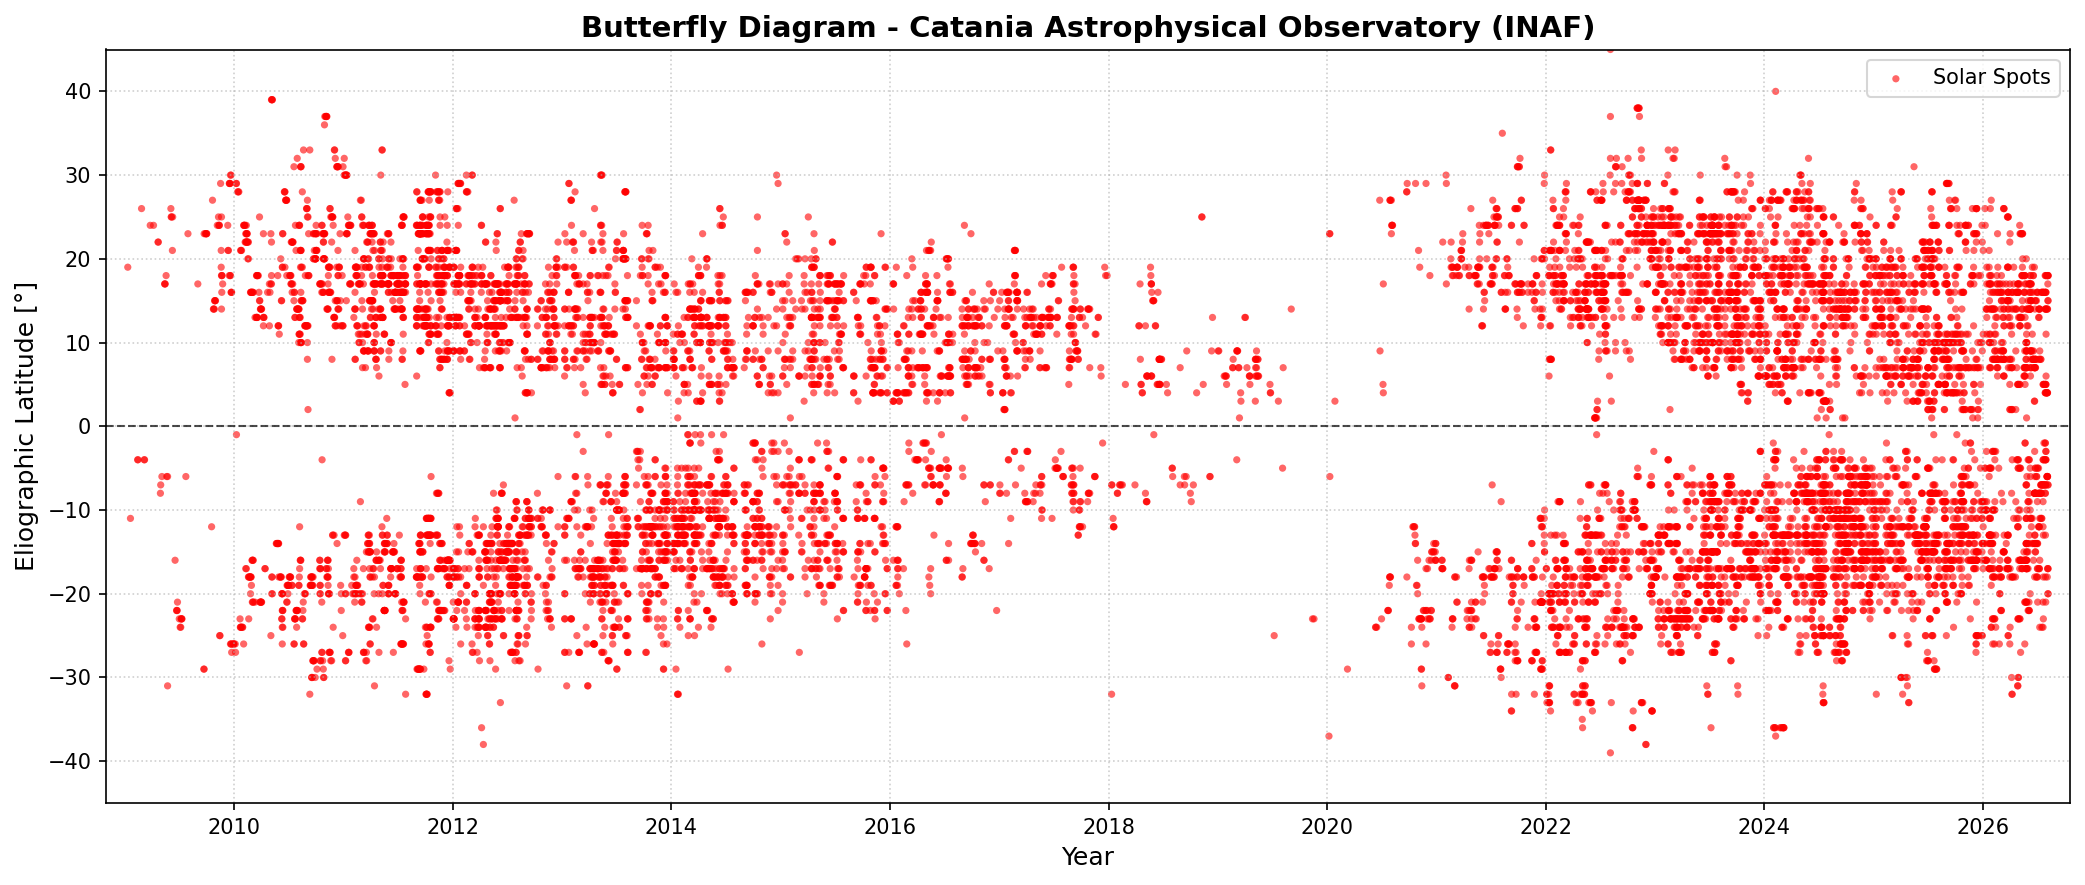

In [4]:
from datetime import datetime
import re
import matplotlib.pyplot as plt
import pandas as pd


def parse_and_plot_butterfly(filename_or_text):
    dates = []
    latitudes = []

    current_date = None

    # If a file path is provided, read it; otherwise, use the string directly
    try:
        with open(filename_or_text, "r") as f:
            lines = f.readlines()
    except (FileNotFoundError, OSError):
        lines = filename_or_text.strip().split("\n")

    for line in lines:
        line = line.strip()
        if not line:
            continue

        # 1. Recognize the change of file/date (ex: 090110.txt)
        match_file = re.search(r"(\d{6})\.txt", line)
        if match_file:
            yymmdd = match_file.group(1)
            # Convert YYMMDD in datetime object (ex. 09 -> 2009, 26 -> 2026)
            dt = datetime.strptime(yymmdd, "%y%m%d")

            # Convert the date in decimal format (ex. 2009.025)
            # to have a continuous and realistic X axis
            year_start = datetime(dt.year, 1, 1)
            year_end = datetime(dt.year + 1, 1, 1)
            frac_year = dt.year + (dt - year_start) / (year_end - year_start)

            current_date = frac_year
            continue

        # 2. Recognize the latitude values (ex: 19NE, 11SW, 04SE, 24NW)
        match_lat = re.match(r"^(\d{2})(NE|NW|SE|SW)$", line)
        if match_lat and current_date is not None:
            deg = int(match_lat.group(1))
            quadrant = match_lat.group(2)

            # Sign: North (+) / South (-)
            lat = deg if quadrant in ["NE", "NW"] else -deg

            dates.append(current_date)
            latitudes.append(lat)

    # DataFrame creation
    df = pd.DataFrame({"Year": dates, "Latitude": latitudes})

    # ==========================================
    # PLOT: BUTTERFLY DIAGRAM
    # ==========================================
    plt.figure(figsize=(14, 6), dpi=150)

    # Scatter plot of data
    plt.scatter(
        df["Year"],
        df["Latitude"],
        c="red",
        s=12,
        alpha=0.6,
        edgecolors="none",
        label="Solar Spots",
    )

    # Sun equator line (Latitude 0°)
    plt.axhline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)

    # Axis labels and title
    plt.title(
        "Butterfly Diagram - Catania Astrophysical Observatory (INAF)",
        fontsize=14,
        fontweight="bold",
    )
    plt.xlabel("Year", fontsize=12)
    plt.ylabel("Eliographic Latitude [°]", fontsize=12)

    # Set axis limits and grid
    plt.ylim(-45, 45)
    plt.xlim(df["Year"].min() - 0.2, df["Year"].max() + 0.2)

    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper right")
    plt.tight_layout()

    # Show and save the plot
    plt.savefig("butterfly_diagram.png", dpi=300)
    plt.show()


# ==========================================
# EXECUTION
# ==========================================
if __name__ == "__main__":
    FILE_NAME = "lat.txt"
    parse_and_plot_butterfly(FILE_NAME)

In the same way, [sunspotsarea](sunspotsarea), generated by [sunspotsarea.c](sunspotsarea.c), reads all the USSPS files stored on the folder [dati_ussps_txt](dati_ussps_txt), extracts the area of every spot, sum the the areas recorded in a single day and stores info in [sunspotsarea.txt](sunspotsarea.txt) \
The next code created [sunspot_area_evolution.png](sunspot_area_evolution.png) from [sunspotsarea.txt](sunspotsarea.txt)

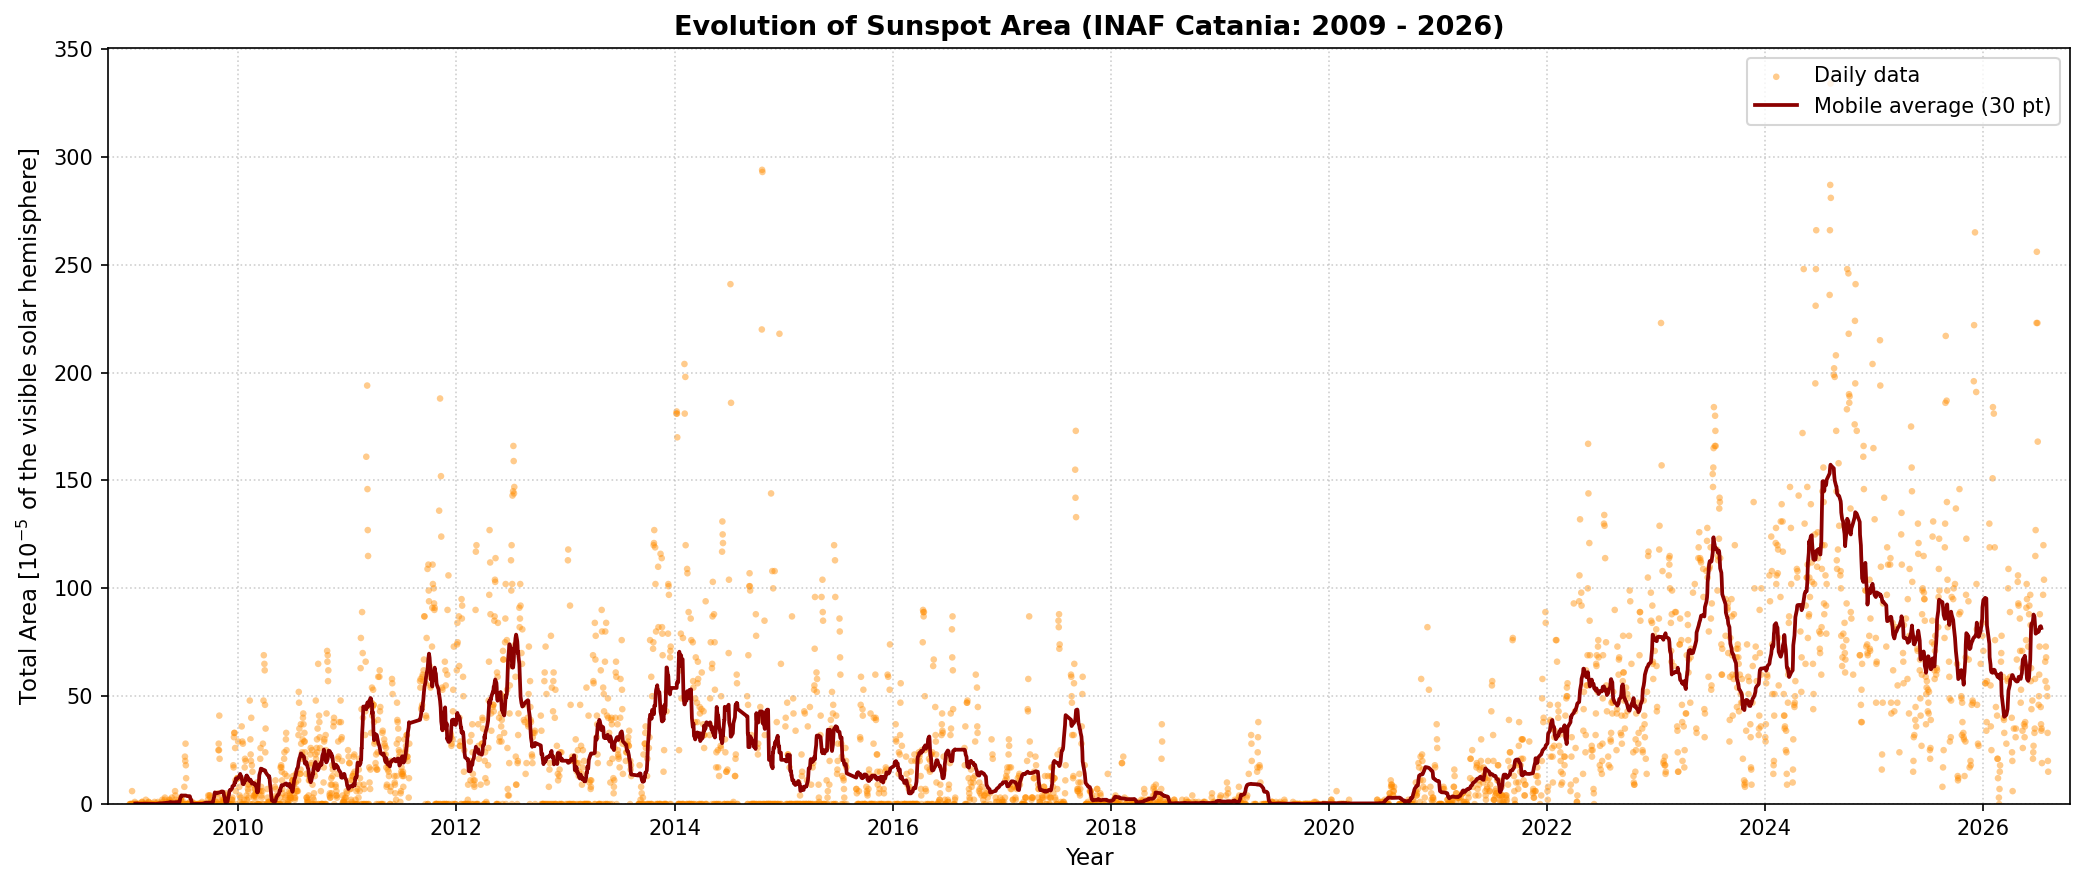

In [1]:
from datetime import datetime
import re
import matplotlib.pyplot as plt
import pandas as pd


def parse_and_plot_sunspot_area(file_path="area.txt"):
    dates = []
    areas = []
    current_year_frac = None

    with open(file_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        line = line.strip()
        if not line:
            continue

        # Extract the date in YYMMDD format from the file name
        match_file = re.search(r"(\d{6})\.txt", line)
        if match_file:
            yymmdd = match_file.group(1)
            dt = datetime.strptime(yymmdd, "%y%m%d")

            # Calculate fractional year for continuous time axis
            year_start = datetime(dt.year, 1, 1)
            year_end = datetime(dt.year + 1, 1, 1)
            current_year_frac = dt.year + (dt - year_start) / (
                year_end - year_start
            )
            continue

        # Extract the area associated with the previous date
        if line.isdigit() and current_year_frac is not None:
            dates.append(current_year_frac)
            areas.append(int(line))
            current_year_frac = None

    df = pd.DataFrame({"Year": dates, "Area": areas})
    df = df.sort_values(by="Year").reset_index(drop=True)

    # Averaging over 30 observations to highlight the solar cycle trend
    df["Area_Smoothed"] = df["Area"].rolling(window=30, center=True).mean()

    # Plotting the data
    plt.figure(figsize=(14, 6), dpi=150)
    plt.scatter(
        df["Year"],
        df["Area"],
        color="darkorange",
        s=10,
        alpha=0.45,
        edgecolors="none",
        label="Daily data",
    )
    plt.plot(
        df["Year"],
        df["Area_Smoothed"],
        color="darkred",
        linewidth=1.8,
        label="Mobile average (30 pt)",
    )

    plt.title(
        "Evolution of Sunspot Area (INAF Catania: 2009 - 2026)",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Year", fontsize=11)
    plt.ylabel(
        "Total Area [$10^{-5}$ of the visible solar hemisphere]", fontsize=11
    )
    plt.xlim(df["Year"].min() - 0.2, df["Year"].max() + 0.2)
    plt.ylim(bottom=0)
    plt.grid(True, linestyle=":", alpha=0.6)
    plt.legend(loc="upper right")
    plt.tight_layout()

    plt.savefig("sunspot_area_evolution.png", dpi=300)
    plt.show()


if __name__ == "__main__":
    parse_and_plot_sunspot_area("sunspotsarea.txt")

Another information we can gain from USSPS files is the dayly number of suspots seen from OACT, that is simply the number of lines of each USSPS not confidering the last one (_INAF-CATANIA ASTROPHYSICAL OBSERVATORY_).
The program that extract data is [spotcount](spotcount), obtained by [spotcount.c](spotcount.c), it stores information in [sunspotscount.txt](sunspotscount.txt). \
The next code creates [sunspots_oact.png](sunspots_oact.png) from the txt file.

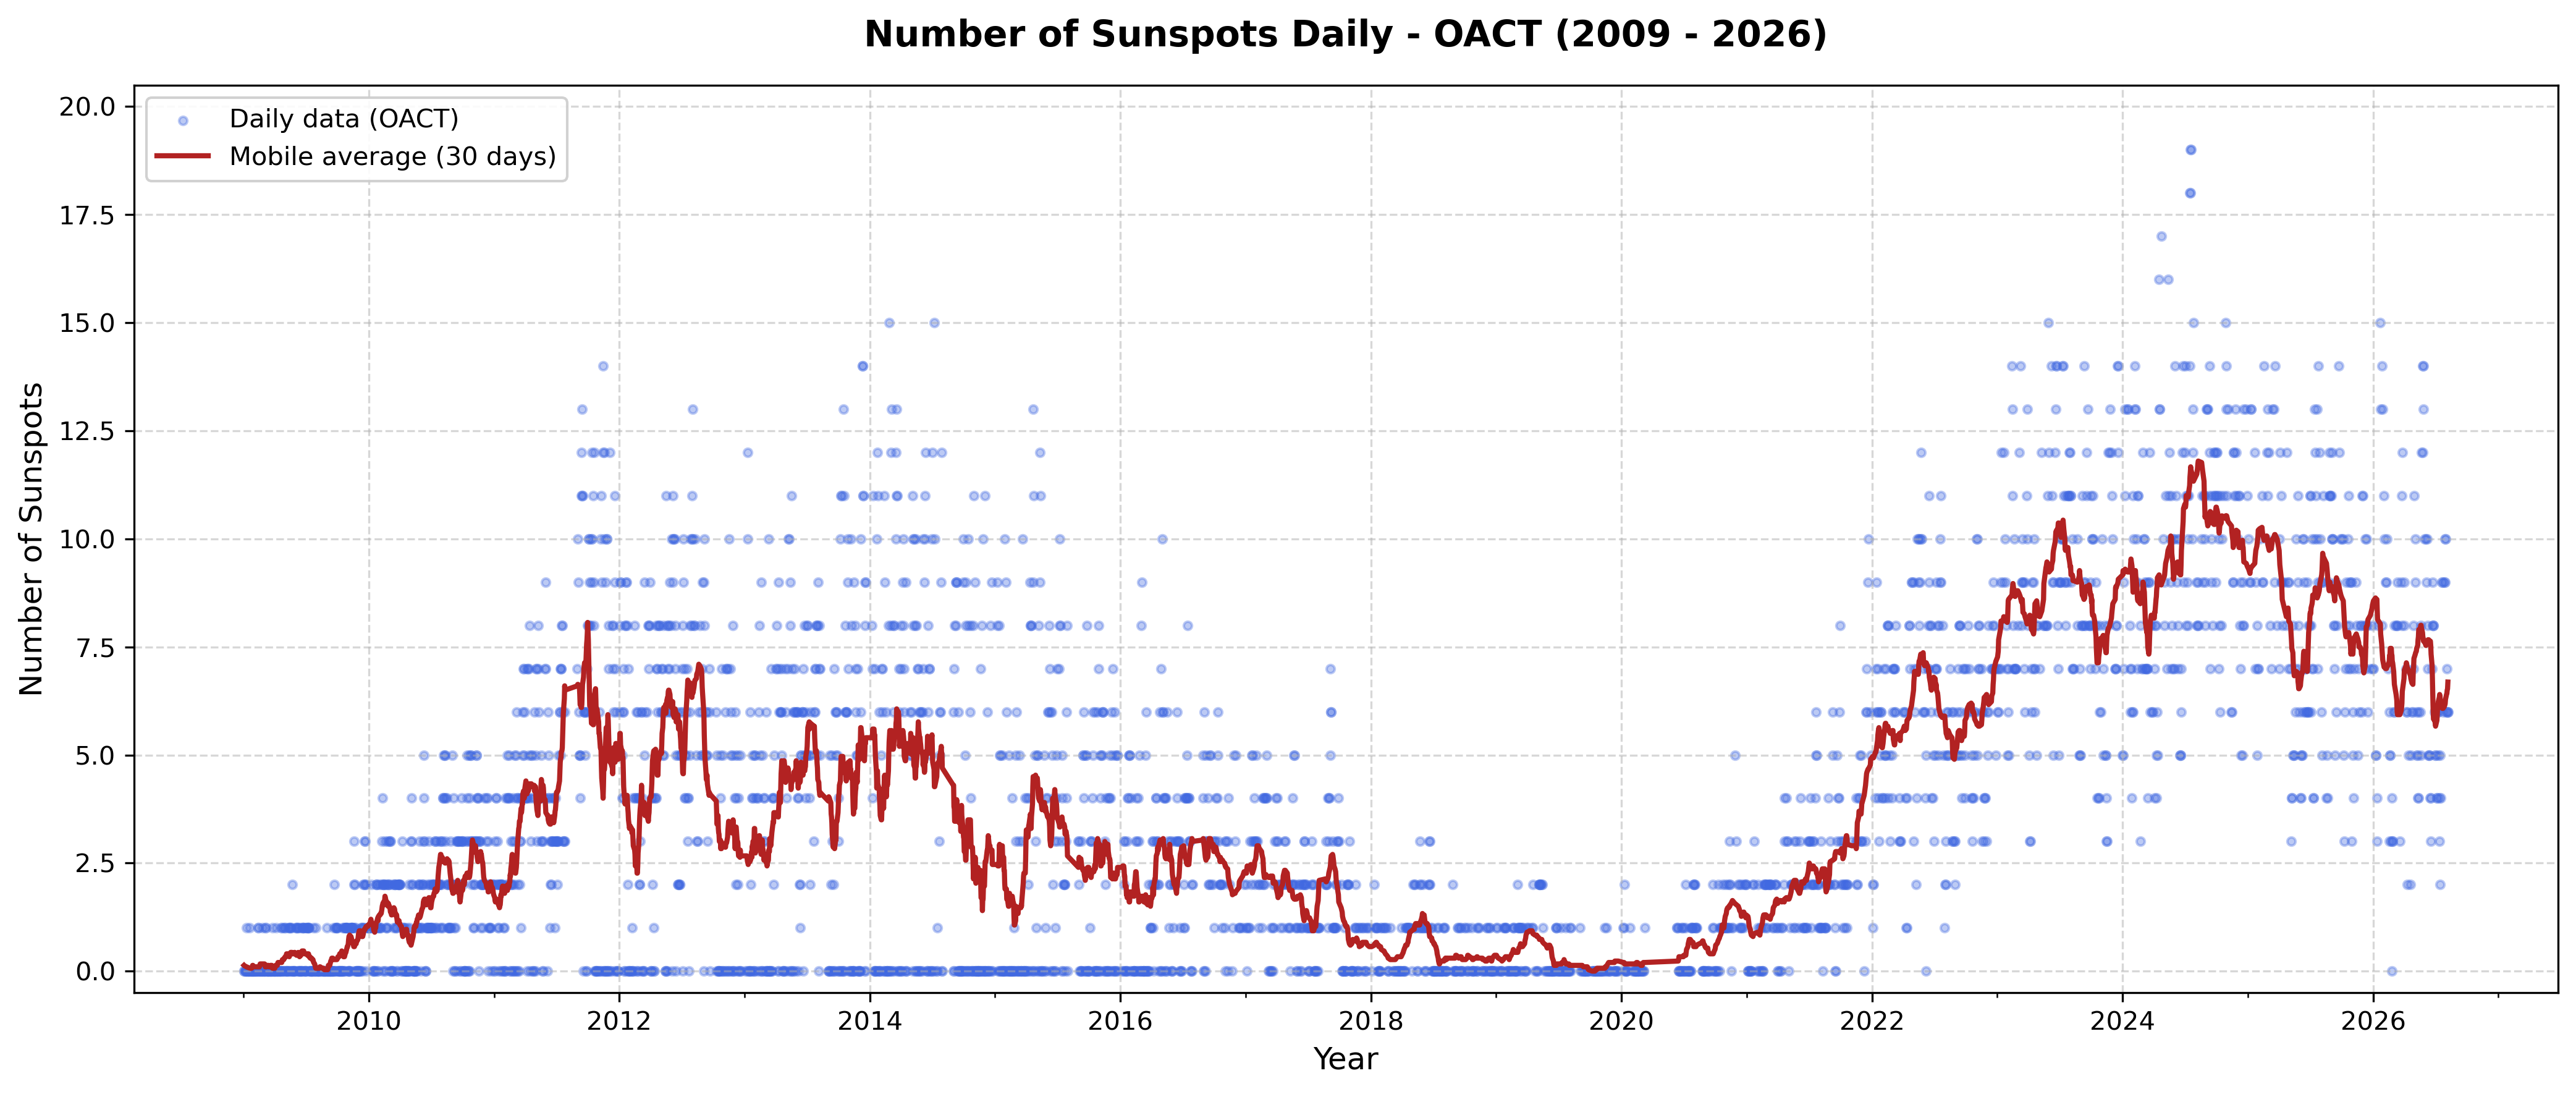

In [2]:
import datetime
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# 1. Reading and parsing the sunspotscount.txt file
records = []
with open('sunspotscount.txt', 'r') as f:
  lines = [line.strip() for line in f if line.strip()]

for i in range(0, len(lines), 2):
  filename = lines[i]
  count = int(lines[i + 1])

  # Extraction of the date (format: YYMMDD)
  base = filename.split('/')[-1].replace('.txt', '')
  year = 2000 + int(base[:2])
  month = int(base[2:4])
  day = int(base[4:6])

  records.append(
      {'date': pd.to_datetime(datetime.date(year, month, day)), 'sunspots': count}
  )

df = pd.DataFrame(records).sort_values('date').reset_index(drop=True)

# 2. Creation of the figure
plt.figure(figsize=(14, 6), dpi=300)

# Daily points
plt.scatter(
    df['date'],
    df['sunspots'],
    color='royalblue',
    alpha=0.35,
    s=10,
    label='Daily data (OACT)',
)

# Mobile average over 30 days
df_rolling = (
    df.set_index('date')['sunspots']
    .rolling(window=30, min_periods=5, center=True)
    .mean()
)
plt.plot(
    df['date'],
    df_rolling,
    color='firebrick',
    linewidth=2,
    label='Mobile average (30 days)',
)

# 3. Formatting and axis details
plt.title(
    'Number of Sunspots Daily - OACT (2009 - 2026)',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Number of Sunspots', fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_ylim(-0.5, df['sunspots'].max() + 1.5)

plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')
plt.tight_layout()

# Saving
plt.savefig('sunspots_oact.png', dpi=300)
plt.show()

We can compare the OACT datas with the SILSO ones. They are stored in [SN_d_tot_V2.0.txt](SN_d_tot_V2.0.txt), downloaded by https://www.sidc.be/SILSO/infosndtot \
The program [SILSO](SILSO), obtained by [SILSO.c](SILSO.c), extract  the dayly sunspotnumber in [SILSOcount.txt](SILSOcount.txt)\
The next code creates [sunspots_SILSO.png](sunspots_SILSO.png) from the txt file.

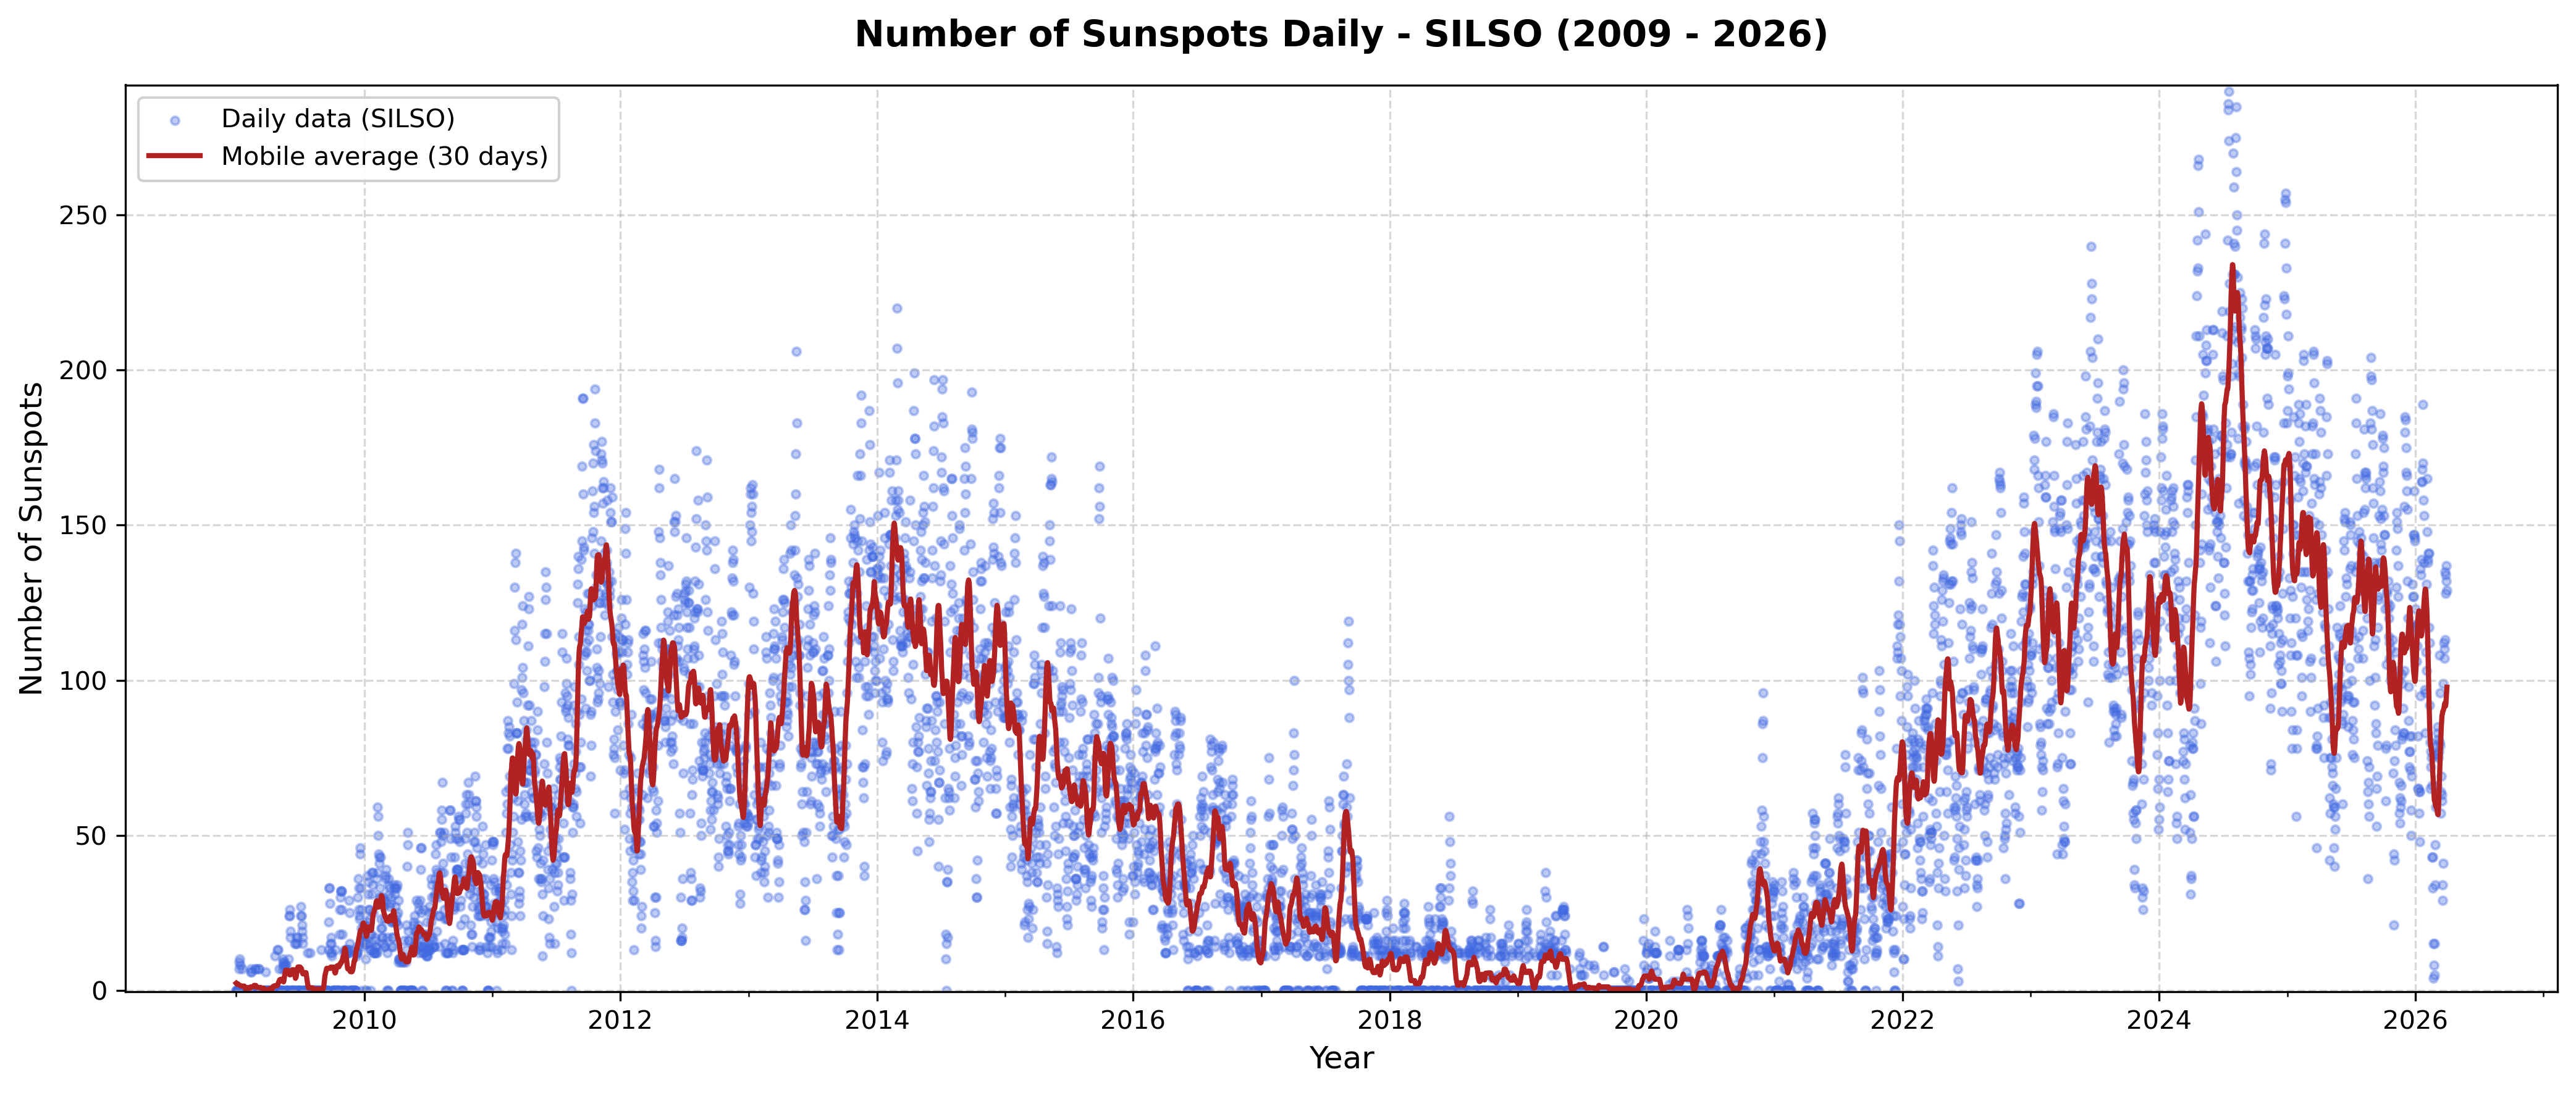

In [3]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

# 1. Reading and parsing the date
df = pd.read_csv(
    "SILSOcount.txt", sep=r"\s+", header=None, names=["data_str", "count"]
)
df["date"] = pd.to_datetime(df["data_str"], format="%Y_%m_%d")

# 2. Definition and application of the MASK
mask = df["date"] >= "2009-01-01"
df_plot = df[mask].sort_values("date").reset_index(drop=True)

# 3. Creation of the figure
plt.figure(figsize=(14, 6), dpi=300)

# Daily points
plt.scatter(
    df_plot["date"],
    df_plot["count"],
    color="royalblue",
    alpha=0.35,
    s=10,
    label="Daily data (SILSO)",
)

# Mobile average over 30 days
df_rolling = (
    df_plot.set_index("date")["count"]
    .rolling(window=30, min_periods=5, center=True)
    .mean()
)

plt.plot(
    df_plot["date"],
    df_rolling,
    color="firebrick",
    linewidth=2,
    label="Mobile average (30 days)",
)

# 4. Formatting and axis details
plt.title(
    "Number of Sunspots Daily - SILSO (2009 - 2026)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Sunspots", fontsize=12)

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(-0.5, df_plot["count"].max() + 2)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(frameon=True, facecolor="white", framealpha=0.9, loc="upper left")
plt.tight_layout()

# Saving
plt.savefig('sunspots_SILSO.png', dpi=300)
plt.show()